# ============= CELLULE 1: CONFIGURATION ET IMPORTS =============

In [1]:

import os
import sys
import cv2
import json
import torch
import numpy as np
import onnxruntime as ort
import time
import onnx
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter

%matplotlib inline

sys.path.append(os.getcwd())
from lib.core.general import non_max_suppression, box_iou, ap_per_class
from lib.core.evaluate import SegmentationMetric


# ============= CONSTANTES DE CONFIGURATION =============

In [2]:

CONF_THRES = 0.001
IOU_THRES = 0.6
IMG_SIZE = 640
BATCH_SIZE = 1 
MAX_IMAGES = None  
TARGET_IMG = "b1c66a42-6f7d68ca.jpg" 

NODES_TO_ANALYZE_CRITIQUE =  []
# Conv, Gemm, MatMul,Mul, Add,Sigmoid, HardSwish, Relu)

# ANALYSE POUSSÉE CONCAT : [Nom_Node, [Liste_Indices]]
# Indices : 0=x, 1=y, 2=w, 3=h, 4=Conf_Obj, 5=Class_Prob
NODES_TO_ANALYZE_CONCAT =  []

ENABLE_LAYER_MINMAX_PLOT = True  # Active le diagramme min/max par nodes
LAYER_VALUE_DISTRIBUTION = 0  

# Chemins
BASE_DIR = os.getcwd()
VAL_DIR = os.path.join(BASE_DIR, "dataset/images/val")
ONNX_PATH = os.path.join(BASE_DIR, "weights/yolop-640-640-normalized-quantized-int8-Entropy.onnx")
ONNX_DEBUG_PATH = os.path.join(BASE_DIR, "weights/temps_debug.onnx")


# ============= CELLULE 1B: CREATION MODELE DEBUG =============

In [3]:
def create_debug_model(input_model_path, output_model_path, target_nodes=[]):
    """Cree une version du modele avec toutes les sorties intermediaires exposees"""
    print(f"\nCreation du modele debug avec sorties intermediaires...")
    
    if os.path.exists(output_model_path):
        os.remove(output_model_path)
    
    model = onnx.load(input_model_path)

    if model.opset_import[0].version < 13:
        print(f"   Mise à jour Opset {model.opset_import[0].version} -> 13 (Patch Anti-Crash)...")
        model.opset_import[0].version = 13
    
    intermediate_outputs = []
    target_ops = ['Conv', 'QLinearConv', 'ConvInteger', 'Gemm', 'MatMul', 'QLinearMatMul', 
                'Add', 'Mul', 'Concat', 'Sigmoid', 'Resize', 'Transpose', 'Reshape']
    
    for node in model.graph.node:
        is_target = False

        if target_nodes:
            if node.name in target_nodes:
                is_target = True

        elif node.op_type in target_ops:
            is_target = True

        if is_target:
            for output in node.output:
                if output:
                    intermediate_outputs.append(output)
    
    print(f"  Extraction de {len(intermediate_outputs)} nodes intermédiaires...")
    
    existing_outputs = [o.name for o in model.graph.output]
    
    for output_name in intermediate_outputs:
        if output_name not in existing_outputs:
            output_value_info = onnx.helper.make_tensor_value_info(
                output_name,
                onnx.TensorProto.FLOAT,
                None 
            )
            model.graph.output.append(output_value_info)
    
    onnx.save(model, output_model_path)
    print(f" Modele debug sauvegarde : {output_model_path}")
    print(f" Nombre total de sorties exposees : {len(model.graph.output)}")
    
    return output_model_path

# ============= CELLULE 2: FONCTION D'AUDIT DU MODELE =============

In [4]:
def audit_model_robust(model_path):
    """Audit detaille de la quantisation du modele ONNX"""
    print(f"\nAUDIT DU MODELE : {os.path.basename(model_path)}")
    print("-" * 70)
    
    if not os.path.exists(model_path):
        print("ERREUR : Fichier introuvable.")
        return
    
    model = onnx.load(model_path)
    graph = model.graph
    
    node_map = {}
    for node in graph.node:
        for output in node.output:
            node_map[output] = node
    
    stats = {
    "Total_Graph_Nodes": len(graph.node), # Le vrai total brut
    "Compute_Nodes": 0,    
    "Quant_Overhead": 0,   
    "Structure_Nodes": 0,  
    "FP32_Compute": 0,
    "INT8_Compute": 0
    }
    
    fp32_layers = []
    int8_qlinear_layers = []
    int8_qdq_layers = []
    
    compute_ops = [
        'Conv', 'Gemm', 'MatMul', 'ConvTranspose',
        'QLinearConv', 'QLinearMatMul', 'QLinearGemm',
        'ConvInteger', 'MatMulInteger'
    ]
   
    for node in graph.node:
        
        if node.op_type in ['QuantizeLinear', 'DequantizeLinear']:
            stats["Quant_Overhead"] += 1
            continue
        if node.op_type in compute_ops:
            stats["Compute_Nodes"] += 1 
            
            layer_name = node.name if node.name else f"{node.op_type}_{stats['Compute_Nodes']}"

            if 'QLinear' in node.op_type or 'Integer' in node.op_type:
                stats["INT8_Compute"] += 1
                int8_qlinear_layers.append((layer_name, node.op_type))
                continue
            
            is_quantized_input = False
            for inp_name in node.input[:2]: 
                if inp_name in node_map:
                    parent = node_map[inp_name]
                    if parent.op_type == "DequantizeLinear":
                        is_quantized_input = True
                        break
            
            if is_quantized_input:
                stats["INT8_Compute"] += 1
                int8_qdq_layers.append((layer_name, node.op_type))
            else:
                stats["FP32_Compute"] += 1
                fp32_layers.append((layer_name, node.op_type))
        
        else:
            stats["Structure_Nodes"] += 1
    
    quant_ratio = (stats["INT8_Compute"] / stats["Compute_Nodes"] * 100) if stats["Compute_Nodes"] > 0 else 0

    print(f"ANALYSE DU GRAPHE ONNX (NODES RÉELS) :")
    print(f"  TOTAL NODES DU GRAPHE  : {stats['Total_Graph_Nodes']} ")
    print(f"  --------------------------------------------------")
    print(f"  Dont Noeuds de Calcul  : {stats['Compute_Nodes']} (Conv, Gemm...)")
    print(f"  Dont Overhead INT8     : {stats['Quant_Overhead']} (Quantize/Dequantize)")
    print(f"  Dont Structure/Misc    : {stats['Structure_Nodes']} (Reshape, Concat...)")
    print(f"  ==================================================")
    print(f"  Détail Calcul (Compute):")
    print(f"    - INT8 (Quantifié)   : {stats['INT8_Compute']}")
    print(f"    - FP32 (Standard)    : {stats['FP32_Compute']}")
    print(f"  Taux de Quantisation   : {quant_ratio:.2f}% (Sur les noeuds de calcul)")
    print("-" * 70)

    if stats["FP32_Compute"] > 0:
        print(f"\nNODES DE CALCUL RESTES EN FP32 ({stats['FP32_Compute']}) :")
        for i, (name, op_type) in enumerate(fp32_layers[:15]):
            print(f"  {i+1:2d}. {name[:50]:50s} ({op_type})")
        if len(fp32_layers) > 15:
            print(f"  ... et {len(fp32_layers) - 15} autres nodes")
    else:
        print("\n  Aucun node FP32 detecté.")
    
    op_types = [op for _, op in int8_qlinear_layers + int8_qdq_layers + fp32_layers]
    op_counts = Counter(op_types)
    
    print(f"\nDISTRIBUTION DES TYPES D'OPERATIONS :")
    for op_type, count in op_counts.most_common():
        print(f"  {op_type:20s} : {count:3d}")
    
    print("-" * 70 + "\n")
    
    return {
    "total": stats["Total_Graph_Nodes"],
    "compute_nodes": stats["Compute_Nodes"],
    "int8_compute": stats["INT8_Compute"],
    "fp32_compute": stats["FP32_Compute"],
    "quantization_ratio": quant_ratio
    }

# ============= CELLULE 3: DatasetImage (Visualisation) =============

In [5]:
class DatasetImage:
    """Classe pour traiter une seule image avec letterbox"""
    
    def __init__(self, img_path, model_path=None, session=None, debug_model_path=None, extra_outputs=[]):
        self.session = session
        self.debug_session = None
        self.img_path = img_path
        self.model_path = model_path
        self.debug_model_path = debug_model_path
        self.extra_outputs = extra_outputs 
        
        if not os.path.exists(self.img_path):
            raise FileNotFoundError(f"Image introuvable : {self.img_path}")
            
        self.img_bgr = cv2.imread(self.img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.h_orig, self.w_orig = self.img_rgb.shape[:2]
        
        self.da_path, self.ll_path, self.det_path = self._get_gt_paths()
        
        self.pred_da = None
        self.pred_ll = None
        self.pred_boxes = None
        self.gt_da = None
        self.gt_ll = None
        self.gt_boxes = None
        
        self.r = None
        self.dw = None
        self.dh = None
        self.new_w = None
        self.new_h = None
        
        self.inference_time = 0
        
        self.layer_outputs = {}
        self.layer_names = {}
    
    def _get_gt_paths(self):
        da_path = self.img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = self.img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = self.img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        return da_path, ll_path, det_path
    
    def _letterbox(self, img, new_shape=640):
        """Letterbox resize avec padding"""
        shape = img.shape[:2]
        if isinstance(new_shape, int):
            new_shape = (new_shape, new_shape)
        
        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
        
        dw = (new_shape[1] - new_unpad[0]) // 2
        dh = (new_shape[0] - new_unpad[1]) // 2
        
        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
        
        top, bottom = dh, new_shape[0] - new_unpad[1] - dh
        left, right = dw, new_shape[1] - new_unpad[0] - dw
        img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        
        return img, r, dw, dh, new_unpad[0], new_unpad[1]
    
    def load_ground_truth(self):
        """Charge les GT avec binarisation"""
        if os.path.exists(self.da_path):
            self.gt_da = cv2.imread(self.da_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_da is not None:
                self.gt_da = (self.gt_da > 0).astype(np.uint8)
                if self.gt_da.shape != (self.h_orig, self.w_orig):
                    self.gt_da = cv2.resize(self.gt_da, (self.w_orig, self.h_orig), 
                                           interpolation=cv2.INTER_NEAREST)
        
        if os.path.exists(self.ll_path):
            self.gt_ll = cv2.imread(self.ll_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_ll is not None:
                self.gt_ll = (self.gt_ll > 0).astype(np.uint8)
                if self.gt_ll.shape != (self.h_orig, self.w_orig):
                    self.gt_ll = cv2.resize(self.gt_ll, (self.w_orig, self.h_orig), 
                                           interpolation=cv2.INTER_NEAREST)
        
        self.gt_boxes = []
        if os.path.exists(self.det_path):
            try:
                with open(self.det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') == 'car':
                            box2d = obj.get('box2d', {})
                            if box2d:
                                self.gt_boxes.append([
                                    0,
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception:
                pass
        
        self.gt_boxes = np.array(self.gt_boxes) if len(self.gt_boxes) > 0 else np.zeros((0, 5))
 
    def run_inference(self, capture_intermediates=True):
        if self.session is None:
            if self.model_path and os.path.exists(self.model_path):
                try:
                    model_head = onnx.load(self.model_path, load_external_data=False)
                    if model_head.opset_import[0].version < 13:
                        print(f" [DatasetImage] Mise à jour Opset {model_head.opset_import[0].version} -> 13 (Requis pour INT8)...")
                        
                        full_model = onnx.load(self.model_path)
                        full_model.opset_import[0].version = 13
                        
                        new_path = self.model_path.replace(".onnx", "_v13.onnx")
                        onnx.save(full_model, new_path)
                        self.model_path = new_path
                except Exception as e:
                    print(f" Attention: Impossible de patcher l'Opset: {e}")

            sess_options = ort.SessionOptions()
            sess_options.log_severity_level = 3
            # Priorité CPU pour éviter les conflits mémoires lors de la visualisation
            providers = ['CPUExecutionProvider'] 
            self.session = ort.InferenceSession(self.model_path, sess_options=sess_options, providers=providers)

        
        img_letterbox, self.r, self.dw, self.dh, self.new_w, self.new_h = self._letterbox(
            self.img_rgb, IMG_SIZE
        )
        
        img_input = img_letterbox.astype(np.float32) / 255.0
        img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)
        
        start_time = time.time()
        
        if capture_intermediates and self.debug_model_path and os.path.exists(self.debug_model_path):
            try:
                if self.debug_session is None:
                    print("Création du mapping Sortie -> Node Name...")
                    tmp_model = onnx.load(self.debug_model_path)
                    output_to_node = {}
                    for node in tmp_model.graph.node:
                        for out in node.output:
                            output_to_node[out] = node.name
                    
                    print("Chargement du modele DEBUG en memoire...")
                    sess_options = ort.SessionOptions()
                    sess_options.log_severity_level = 3
                    self.debug_session = ort.InferenceSession(
                        self.debug_model_path, 
                        sess_options=sess_options, 
                        providers=['CPUExecutionProvider']
                    )
                
                output_names = [o.name for o in self.debug_session.get_outputs()]
                print(f"Execution du modele debug ({len(output_names)} nodess)...")
                
                outputs_list = self.debug_session.run(
                    output_names,
                    {self.debug_session.get_inputs()[0].name: img_input}
                )
                
                final_heads = [o.name for o in self.session.get_outputs()]
                
                self.layer_outputs = {}
                self.layer_names = {}
                
                idx_counter = 0
                for i, name in enumerate(output_names):
                    output_data = outputs_list[i]
                    if isinstance(output_data, np.ndarray) and len(output_data.shape) >= 2:
                        if output_data.size > 0:
                            real_name = output_to_node.get(name, name)
                            self.layer_outputs[idx_counter] = output_data
                            self.layer_names[idx_counter] = real_name
                            idx_counter += 1
                        
                print(f" Capture reussie de {len(self.layer_outputs)} nodes internes.")
                
            except Exception as e:
                print(f" Erreur lors de la capture debug : {e}")
                import traceback
                traceback.print_exc()
        
        start_time = time.time()
        
        fetch_list = ['det_out', 'drive_area_seg', 'lane_line_seg'] + self.extra_outputs
        
        outputs = self.session.run(
            fetch_list,
            {self.session.get_inputs()[0].name: img_input} 
        )
        self.inference_time = (time.time() - start_time) * 1000
        
        det_out = outputs[0]
        da_seg_out = outputs[1]
        ll_seg_out = outputs[2]
        
        if det_out.shape[-1] >= 4:
            det_out_denorm = det_out.copy()
            det_out_denorm[..., :4] *= IMG_SIZE  
            det_out = det_out_denorm

        da_pred = np.argmax(da_seg_out, axis=1)[0]
        ll_pred = np.argmax(ll_seg_out, axis=1)[0]
        
        da_pred = da_pred[self.dh : self.dh + self.new_h, self.dw : self.dw + self.new_w]
        ll_pred = ll_pred[self.dh : self.dh + self.new_h, self.dw : self.dw + self.new_w]
        
        self.pred_da = cv2.resize(da_pred.astype(np.uint8), (self.w_orig, self.h_orig), 
                                  interpolation=cv2.INTER_NEAREST)
        self.pred_ll = cv2.resize(ll_pred.astype(np.uint8), (self.w_orig, self.h_orig), 
                                  interpolation=cv2.INTER_NEAREST)
        
        det_tensor = torch.from_numpy(det_out).float()
        nms_out = non_max_suppression(det_tensor, conf_thres=CONF_THRES, iou_thres=IOU_THRES)
        
        if nms_out[0] is not None and len(nms_out[0]) > 0:
            pred_boxes = nms_out[0].cpu().numpy()
            pred_boxes[:, [0, 2]] -= self.dw
            pred_boxes[:, [1, 3]] -= self.dh
            pred_boxes[:, :4] /= self.r
            pred_boxes[:, 0] = np.clip(pred_boxes[:, 0], 0, self.w_orig)
            pred_boxes[:, 2] = np.clip(pred_boxes[:, 2], 0, self.w_orig)
            pred_boxes[:, 1] = np.clip(pred_boxes[:, 1], 0, self.h_orig)
            pred_boxes[:, 3] = np.clip(pred_boxes[:, 3], 0, self.h_orig)
            self.pred_boxes = pred_boxes
        else:
            self.pred_boxes = np.zeros((0, 6))

    def visualize(self):
        """Genere la visualisation : Originale | GT | Prediction"""
        def draw_overlay(img, da, ll, boxes, box_type='pred', color=(0, 255, 0)):
            res = img.copy()
            color_mask = np.zeros_like(res)
            if da is not None: 
                color_mask[da == 1] = [0, 255, 0]
            if ll is not None: 
                color_mask[ll == 1] = [255, 0, 0]
            
            mask_indices = np.any(color_mask != 0, axis=-1)
            res[mask_indices] = res[mask_indices] * 0.6 + color_mask[mask_indices] * 0.4
            
            if boxes is not None and len(boxes) > 0:
                for box in boxes:
                    if box_type == 'gt': 
                        x1, y1, x2, y2 = map(int, box[1:5])
                    else: 
                        x1, y1, x2, y2 = map(int, box[:4])
                    cv2.rectangle(res, (x1, y1), (x2, y2), color, 2)
            return res
        
        viz_gt = draw_overlay(self.img_rgb, self.gt_da, self.gt_ll, self.gt_boxes, 'gt', (255, 255, 0))
        viz_pred = draw_overlay(self.img_rgb, self.pred_da, self.pred_ll, self.pred_boxes, 'pred', (0, 140, 255))
        
        plt.figure(figsize=(24, 8))
        
        plt.subplot(1, 3, 1)
        plt.imshow(self.img_rgb)
        plt.title("Image Originale")
        plt.axis('off')
        
        plt.subplot(1, 3, 2)
        plt.imshow(viz_gt)
        plt.title("Realite Terrain (GT)\n(Jaune=Autos, Vert=Route, Rouge=Lignes)")
        plt.axis('off')
        
        plt.subplot(1, 3, 3)
        plt.imshow(viz_pred)
        plt.title("Prediction Modele\n(Orange=Autos, Vert=Route, Rouge=Lignes)")
        plt.axis('off')
        
        plt.tight_layout()
        plt.show()
    
    def plot_layer_minmax(self):
        """Diagramme min/max par nodes (uniquement si batch=1 et ENABLE_LAYER_MINMAX_PLOT=True)"""
        if not self.layer_outputs:
            print("Aucune donnee de nodes capturee. Executez run_inference avec capture_intermediates=True")
            return
        
        layer_nums = []
        layer_mins = []
        layer_maxs = []
        
        for layer_num in sorted(self.layer_outputs.keys()):
            output = self.layer_outputs[layer_num]
            layer_nums.append(layer_num)
            layer_mins.append(np.min(output))
            layer_maxs.append(np.max(output))
        
        plt.figure(figsize=(16, 6))
        tick_labels = [self.layer_names[i] for i in layer_nums]
        plt.xticks(layer_nums, tick_labels, rotation=90, fontsize=8)
        
        plt.stem(layer_nums, layer_maxs, linefmt='g-', markerfmt='go', basefmt='k-', label='Maximum')
        plt.stem(layer_nums, layer_mins, linefmt='r-', markerfmt='ro', basefmt='k-', label='Minimum')
        plt.axhline(y=0, color='k', linestyle='--', alpha=0.3)
        plt.xlabel('Noeuds (Séquentiel)')
        plt.ylabel('Valeur')
        plt.title(f'Valeurs Min/Max par Node ({len(self.layer_outputs)} nodes analysés)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        print(f"\nStatistiques des nodes capturees:")
        print(f"  Nombre de nodes: {len(self.layer_outputs)}")
        print(f"  Min global: {min(layer_mins):.4f}")
        print(f"  Max global: {max(layer_maxs):.4f}")
        if len(self.layer_outputs) > 0:
            print(f"\nPremiere nodes: Index 0 - {self.layer_names[0]}")
            print(f"Derniere nodes: Index {max(layer_nums)} - {self.layer_names[max(layer_nums)]}")
    
    def plot_layer_distribution(self, layer_k):
        """Histogramme de distribution des valeurs pour une nodes k"""
        # Si layer_k est un nom (str), on cherche son index
        if isinstance(layer_k, str):
            found_idx = None
            for idx, name in self.layer_names.items():
                if name == layer_k:
                    found_idx = idx
                    break
            if found_idx is None:
                print(f"Node nommé '{layer_k}' introuvable dans les données capturées.")
                return
            layer_k = found_idx
            
        if layer_k not in self.layer_outputs:
            print(f"nodes {layer_k} non disponible.")
            print(f"nodess capturees disponibles: indices de 0 a {len(self.layer_outputs)-1}")
            if len(self.layer_outputs) > 0:
                print(f"\nQuelques exemples:")
                for i in sorted(self.layer_outputs.keys())[:5]:
                    print(f"  Index {i}: {self.layer_names[i]}")
                if len(self.layer_outputs) > 5:
                    print(f"  ...")
            return
        
        output = self.layer_outputs[layer_k]
        values = output.flatten()
        
        plt.figure(figsize=(12, 6))
        plt.hist(values, bins=100, edgecolor='black', alpha=0.7, color='steelblue')
        plt.xlabel('Valeur')
        plt.ylabel('Frequence')
        
        # Nom de la nodes
        layer_name = self.layer_names[layer_k]
        plt.title(f'Distribution des valeurs - nodes {layer_k}: {layer_name}')
        plt.grid(True, alpha=0.3)
        
        # Ajouter des statistiques
        stats_text = f'Min: {np.min(values):.4f}\nMax: {np.max(values):.4f}\nMoyenne: {np.mean(values):.4f}\nMediane: {np.median(values):.4f}\nEcart-type: {np.std(values):.4f}\nNombre de valeurs: {len(values)}'
        plt.text(0.02, 0.98, stats_text, transform=plt.gca().transAxes, 
                fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
        
        plt.tight_layout()
        plt.show()
        
    def plot_concat_specifics(self, concat_config):
        """Trace les distributions spécifiques pour les indices demandés du Concat"""
        if not self.layer_outputs:
            print("  Aucune donnée capturée pour l'analyse Concat.")
            return

        for node_name, indices in concat_config:
            # 1. Retrouver l'ID du node
            found_idx = None
            for idx, name in self.layer_names.items():
                if name == node_name:
                    found_idx = idx
                    break
            
            if found_idx is None:
                print(f"  Node {node_name} non trouvé dans les captures.")
                continue

            # 2. Récupérer les données (Shape: 1, 25200, 6)
            data = self.layer_outputs[found_idx]
            # On supprime la dimension batch (25200, 6)
            data = data[0] 

            # 3. Graphes
            print(f"\n Analyse Poussée pour l'image unique : {node_name}")
            target_indices = range(data.shape[-1]) if (indices is None or indices == [None]) else indices
            
            plt.figure(figsize=(20, 4 * ((len(target_indices)+1)//2)))
            
            for i, channel_idx in enumerate(target_indices):
                if channel_idx >= data.shape[-1]: continue
                
                values = data[:, channel_idx]
                
                plt.subplot((len(target_indices)+1)//2, 2, i+1)
                plt.hist(values, bins=100, color='orangered', alpha=0.7, log=True)
                plt.title(f"Canal {channel_idx} (Log Scale)\nMin:{np.min(values):.2f} | Max:{np.max(values):.2f}")
                plt.grid(True, alpha=0.3)
                
            plt.tight_layout()
            plt.show()


# ============= CELLULE 4: DatasetBatch (Inference par batch) =============

In [6]:
class DatasetBatch:
    """Classe pour traiter des images par batch (optimisation vitesse)"""
    
    def __init__(self, img_paths, session, batch_size=8, extra_outputs=[]):
        self.img_paths = img_paths
        self.session = session
        self.batch_size = batch_size
        self.extra_outputs = extra_outputs 
        self.results = []
    
    @staticmethod
    def letterbox(img, new_shape=640):
        """Letterbox resize statique pour batch processing"""
        shape = img.shape[:2]
        if isinstance(new_shape, int):
            new_shape = (new_shape, new_shape)
        
        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
        
        dw = (new_shape[1] - new_unpad[0]) // 2
        dh = (new_shape[0] - new_unpad[1]) // 2
        
        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
        
        top, bottom = dh, new_shape[0] - new_unpad[1] - dh
        left, right = dw, new_shape[1] - new_unpad[0] - dw
        img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        
        return img, r, dw, dh, new_unpad[0], new_unpad[1]
    
    def load_ground_truth(self, img_path):
        """Charge les GT pour une image"""
        da_path = img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        
        img = cv2.imread(img_path)
        h_orig, w_orig = img.shape[:2]
        
        gt_da = None
        if os.path.exists(da_path):
            gt_da = cv2.imread(da_path, cv2.IMREAD_GRAYSCALE)
            if gt_da is not None:
                gt_da = (gt_da > 0).astype(np.uint8)
                if gt_da.shape != (h_orig, w_orig):
                    gt_da = cv2.resize(gt_da, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
        
        gt_ll = None
        if os.path.exists(ll_path):
            gt_ll = cv2.imread(ll_path, cv2.IMREAD_GRAYSCALE)
            if gt_ll is not None:
                gt_ll = (gt_ll > 0).astype(np.uint8)
                if gt_ll.shape != (h_orig, w_orig):
                    gt_ll = cv2.resize(gt_ll, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
        
        gt_boxes = []
        if os.path.exists(det_path):
            try:
                with open(det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') == 'car':
                            box2d = obj.get('box2d', {})
                            if box2d:
                                gt_boxes.append([
                                    0,
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception:
                pass
        
        gt_boxes = np.array(gt_boxes) if len(gt_boxes) > 0 else np.zeros((0, 5))
        
        return gt_da, gt_ll, gt_boxes, h_orig, w_orig
    
    def process_batch(self, batch_paths):
        """Traite un batch d'images"""
        batch_images = []
        batch_metadata = []
        
        for img_path in batch_paths:
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            h_orig, w_orig = img_rgb.shape[:2]
            
            img_letterbox, r, dw, dh, new_w, new_h = self.letterbox(img_rgb, IMG_SIZE)
            
            img_input = img_letterbox.astype(np.float32) / 255.0
            img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
            img_input = img_input.transpose(2, 0, 1)
            
            batch_images.append(img_input)
            batch_metadata.append({
                'path': img_path,
                'h_orig': h_orig,
                'w_orig': w_orig,
                'r': r,
                'dw': dw,
                'dh': dh,
                'new_w': new_w,
                'new_h': new_h
            })
        
        batch_input = np.array(batch_images, dtype=np.float32)
        
        start_time = time.time()
        
        fetch_list = ['det_out', 'drive_area_seg', 'lane_line_seg'] + self.extra_outputs
        
        outputs = self.session.run(
            fetch_list,
            {self.session.get_inputs()[0].name: batch_input}
        )
        batch_time = (time.time() - start_time) * 1000
        
        det_out = outputs[0]
        da_seg_out = outputs[1]
        ll_seg_out = outputs[2]
        extra_data = outputs[3:] if len(outputs) > 3 else []

        if det_out.shape[-1] >= 4:
            det_out_denorm = det_out.copy()
            det_out_denorm[..., :4] *= IMG_SIZE  
            det_out = det_out_denorm
        
        for i, metadata in enumerate(batch_metadata):
            
            da_pred = np.argmax(da_seg_out[i], axis=0)
            ll_pred = np.argmax(ll_seg_out[i], axis=0)
            
            dh, dw = metadata['dh'], metadata['dw']
            new_h, new_w = metadata['new_h'], metadata['new_w']
            
            da_pred = da_pred[dh:dh+new_h, dw:dw+new_w]
            ll_pred = ll_pred[dh:dh+new_h, dw:dw+new_w]
            
            h_orig, w_orig = metadata['h_orig'], metadata['w_orig']
            pred_da = cv2.resize(da_pred.astype(np.uint8), (w_orig, h_orig), 
                                interpolation=cv2.INTER_NEAREST)
            pred_ll = cv2.resize(ll_pred.astype(np.uint8), (w_orig, h_orig), 
                                interpolation=cv2.INTER_NEAREST)
            
            det_tensor = torch.from_numpy(det_out[i:i+1]).float()
            nms_out = non_max_suppression(det_tensor, conf_thres=CONF_THRES, iou_thres=IOU_THRES)
            
            if nms_out[0] is not None and len(nms_out[0]) > 0:
                pred_boxes = nms_out[0].cpu().numpy()
                
                r = metadata['r']
                pred_boxes[:, [0, 2]] -= dw
                pred_boxes[:, [1, 3]] -= dh
                pred_boxes[:, :4] /= r
                
                pred_boxes[:, 0] = np.clip(pred_boxes[:, 0], 0, w_orig)
                pred_boxes[:, 2] = np.clip(pred_boxes[:, 2], 0, w_orig)
                pred_boxes[:, 1] = np.clip(pred_boxes[:, 1], 0, h_orig)
                pred_boxes[:, 3] = np.clip(pred_boxes[:, 3], 0, h_orig)
            else:
                pred_boxes = np.zeros((0, 6))
            
            gt_da, gt_ll, gt_boxes, _, _ = self.load_ground_truth(metadata['path'])
            
            
            current_extras = {}
            for k, name in enumerate(self.extra_outputs):
                current_extras[name] = extra_data[k][i]

            self.results.append({
                'path': metadata['path'],
                'pred_da': pred_da,
                'pred_ll': pred_ll,
                'pred_boxes': pred_boxes,
                'gt_da': gt_da,
                'gt_ll': gt_ll,
                'gt_boxes': gt_boxes,
                'extras': current_extras,
                'time': batch_time / max(1, len(batch_paths))
            })
    
    def process_all(self):
        """Traite toutes les images par batch"""
        num_batches = (len(self.img_paths) + self.batch_size - 1) // self.batch_size
        
        for i in tqdm(range(num_batches), desc="Processing batches"):
            start_idx = i * self.batch_size
            end_idx = min((i + 1) * self.batch_size, len(self.img_paths))
            batch_paths = self.img_paths[start_idx:end_idx]
            
            try:
                self.process_batch(batch_paths)
            except Exception as e:
                print(f"\nErreur batch {i}: {e}")
                for path in batch_paths:
                    try:
                        self.process_batch([path])
                    except Exception as e2:
                        print(f"Erreur image {os.path.basename(path)}: {e2}")


# ============= CELLULE 5: DatasetFull (Evaluation complete) =============

In [7]:
# %% [markdown]
# # ============= CELLULE 5: DatasetFull (Evaluation complete) =============

# %%
class DatasetFull:
    """Evaluation complete du dataset avec inference par batch"""
    def __init__(self, img_dir, model_path, max_images=None, batch_size=8, concat_config=[], debug_path=None):
        self.img_dir = img_dir
        self.model_path = model_path
        self.batch_size = batch_size
        self.concat_config = concat_config
        self.debug_path = debug_path
        self.global_accumulator = {}
        self.image_files = sorted([
            os.path.join(img_dir, f)
            for f in os.listdir(img_dir)
            if f.endswith('.jpg')
        ])
        if max_images:
            self.image_files = self.image_files[:max_images]
        print(f"Dataset: {len(self.image_files)} images (batch_size={batch_size})")
        
        self.session = None
        if self.model_path and os.path.exists(self.model_path):
            try:
                tmp_model = onnx.load(self.model_path)
                if tmp_model.opset_import[0].version < 13:
                    print(f" Mise à jour Opset {tmp_model.opset_import[0].version} -> 13 (Requis pour INT8 Per-Channel)...")
                    tmp_model.opset_import[0].version = 13
                    self.model_path = self.model_path.replace(".onnx", "_v13.onnx")
                    onnx.save(tmp_model, self.model_path)
            except Exception as e:
                print(f" Echec du patch Opset : {e}")

            sess_options = ort.SessionOptions()
            sess_options.log_severity_level = 3
            providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
            print("Chargement du modele ONNX...")
            target_path = self.model_path
            if self.concat_config and self.debug_path and os.path.exists(self.debug_path):
                print(f" Mode Analyse Globale : Utilisation du modèle DEBUG pour capturer les internes...")
                target_path = self.debug_path
                
            self.session = ort.InferenceSession(
                target_path, 
                sess_options=sess_options, 
                providers=providers
            )

        self.da_metric = SegmentationMetric(2)
        self.ll_metric = SegmentationMetric(2)
        self.det_stats = []
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.iouv = torch.linspace(0.5, 0.95, 10).to(device)
        self.niou = self.iouv.numel()
        self.device = device
        self.times = []

    def process_all(self):
        """Traitement par batch de toutes les images"""
        extra_fetches = []
        fetch_map = {}
        
        if self.concat_config:
            model_source = self.debug_path if (self.debug_path and os.path.exists(self.debug_path)) else self.model_path
            tmp_model = onnx.load(model_source)
            node_to_tensor = {}
            for n in tmp_model.graph.node:
                if n.output:
                    node_to_tensor[n.name] = n.output[0]
            
            for node_name, indices in self.concat_config:
                if node_name in node_to_tensor:
                    tensor_name = node_to_tensor[node_name]
                    extra_fetches.append(tensor_name)
                    fetch_map[tensor_name] = node_name
                    print(f" [Mapping] Node '{node_name}' -> Tensor '{tensor_name}'")
                    self.global_accumulator[node_name] = {}
                    if indices and indices != [None]:
                        for idx in indices:
                            self.global_accumulator[node_name][idx] = []
                else:
                    print(f" ATTENTION : Le node '{node_name}' n'existe pas !")

        print("Evaluation en cours...")
        batch_processor = DatasetBatch(self.image_files, self.session, self.batch_size, extra_outputs=extra_fetches)
        batch_processor.process_all()

        for result in batch_processor.results:
            self.times.append(result['time'])
            
            if result['pred_da'] is not None and result['gt_da'] is not None:
                self.da_metric.addBatch(result['pred_da'], result['gt_da'])
            
            if result['pred_ll'] is not None and result['gt_ll'] is not None:
                self.ll_metric.addBatch(result['pred_ll'], result['gt_ll'])
            
            if 'extras' in result and result['extras']:
                for tensor_name, data in result['extras'].items():
                    node_name = fetch_map.get(tensor_name)
                    if not node_name: continue
                    
                    cfg_indices = next((item[1] for item in self.concat_config if item[0] == node_name), None)
                    if cfg_indices is None or cfg_indices == [None]:
                        cfg_indices = range(data.shape[-1])
                    
                    for ch_idx in cfg_indices:
                        if ch_idx < data.shape[-1]:
                            if node_name not in self.global_accumulator: self.global_accumulator[node_name] = {}
                            if ch_idx not in self.global_accumulator[node_name]: self.global_accumulator[node_name][ch_idx] = []
                            self.global_accumulator[node_name][ch_idx].extend(data[:, ch_idx].flatten())

            self._process_detection_stats(
                result['pred_boxes'],
                result['gt_boxes']
            )

    def _process_detection_stats(self, pred_boxes, gt_boxes):
        """Calcule les stats de detection"""
        pred = torch.from_numpy(pred_boxes).float().to(self.device)
        labels = torch.from_numpy(gt_boxes).float().to(self.device)
        nl = len(labels)
        tcls = labels[:, 0].tolist() if nl else []
        
        if len(pred) == 0:
            if nl:
                self.det_stats.append((
                    torch.zeros(0, self.niou, dtype=torch.bool),
                    torch.Tensor(),
                    torch.Tensor(),
                    tcls
                ))
            return

        correct = torch.zeros(pred.shape[0], self.niou, dtype=torch.bool, device=self.device)
        if nl:
            detected = []
            tcls_tensor = labels[:, 0]
            tbox = labels[:, 1:5]
            for cls in torch.unique(tcls_tensor):
                ti = (tcls_tensor == cls).nonzero(as_tuple=False).view(-1)
                pi = (pred[:, 5] == cls).nonzero(as_tuple=False).view(-1)
                if pi.shape[0]:
                    ious, idx = box_iou(pred[pi, :4], tbox[ti]).max(1)
                    for j in (ious > self.iouv[0]).nonzero(as_tuple=False):
                        d = ti[idx[j]]
                        if d.item() not in detected:
                            detected.append(d.item())
                            correct[pi[j]] = ious[j] > self.iouv
                            if len(detected) == nl:
                                break
        
        self.det_stats.append((
            correct.cpu(), 
            pred[:, 4].cpu(), 
            pred[:, 5].cpu(), 
            tcls
        ))

    def compute_metrics(self):
        """Calcul des metriques finales"""
        print("\n" + "="*60)
        print("YOLOP EVALUATION RESULTS")
        print("="*60)
        
        # Speed
        avg_time = np.mean(self.times)
        fps = 1000 / avg_time if avg_time > 0 else 0
        
        # Detection
        recall_val = 0.0
        map50_val = 0.0
        if len(self.det_stats):
            stats = [np.concatenate(x, 0) for x in zip(*self.det_stats)]
            if stats[0].any():
                p, r, ap, f1, ap_class = ap_per_class(
                    *stats, plot=False, save_dir=None, names={0: 'car'}
                )
                ap50 = ap[:, 0]
                recall_val = r.mean()
                map50_val = ap50.mean()

        print("Traffic Object Detection Result")
        print(f"  Recall(%): {recall_val*100:.2f}")
        print(f"  Speed(fps): {fps:.2f}")
        print(f"  mAP50(%): {map50_val*100:.2f}")

        # Drivable Area Segmentation
        da_miou = self.da_metric.meanIntersectionOverUnion()
        print("Drivable Area Segmentation Result")
        print(f"  mIOU(%): {da_miou*100:.2f}")
        print(f"  Speed(fps): {fps:.2f}")

        # Lane Detection
        ll_miou = self.ll_metric.meanIntersectionOverUnion()
        ll_iou = self.ll_metric.IntersectionOverUnion()
        print("Lane Detection Result")
        print(f"  mIOU(%): {ll_miou*100:.2f}")
        print(f"  IOU(%): {ll_iou*100:.2f}")
        print("="*60)

        if self.global_accumulator:
            print("\n" + "="*60)
            print("ANALYSE STATISTIQUE GLOBALE (DATASET COMPLET)")
            print("="*60)
            for node_name, channels_data in self.global_accumulator.items():
                print(f" Node : {node_name}")
                sorted_channels = sorted(channels_data.keys())
                plt.figure(figsize=(20, 4 * ((len(sorted_channels)+1)//2)))
                plt.suptitle(f"Analyse Globale : {node_name}", fontsize=16)
                for i, ch_idx in enumerate(sorted_channels):
                    values = np.array(channels_data[ch_idx])
                    if len(values) > 0:
                        plt.subplot((len(sorted_channels)+1)//2, 2, i+1)
                        plt.hist(values, bins=100, color='purple', alpha=0.7, log=True)
                        plt.title(f"Canal {ch_idx} (Global)\nN={len(values)} | Min:{np.min(values):.2f} | Max:{np.max(values):.2f}")
                        plt.grid(True, alpha=0.3)
                plt.tight_layout()
                plt.show()

# ============= CELLULE 6: MAIN =============


DIAGNOSTIC MATERIEL
PyTorch : CUDA (GPU)
  Carte Graphique : NVIDIA GeForce RTX 5060 Ti
  Memoire VRAM    : 16.61 GB
----------------------------------------------------------------------
ONNX Runtime Providers : ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
ONNX peut utiliser le GPU (CUDA detecte)


AUDIT DU MODELE : yolop-640-640-normalized-quantized-int8-Entropy.onnx
----------------------------------------------------------------------
ANALYSE DU GRAPHE ONNX (NODES RÉELS) :
  TOTAL NODES DU GRAPHE  : 1565 
  --------------------------------------------------
  Dont Noeuds de Calcul  : 102 (Conv, Gemm...)
  Dont Overhead INT8     : 1099 (Quantize/Dequantize)
  Dont Structure/Misc    : 364 (Reshape, Concat...)
  Détail Calcul (Compute):
    - INT8 (Quantifié)   : 102
    - FP32 (Standard)    : 0
  Taux de Quantisation   : 100.00% (Sur les noeuds de calcul)
----------------------------------------------------------------------

  Aucun node FP32 detec

/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:234: UserWarning: 
NVIDIA GeForce RTX 5060 Ti with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_52 sm_60 sm_61 sm_70 sm_72 sm_75 sm_80 sm_86 sm_87 sm_90 compute_90.
If you want to use the NVIDIA GeForce RTX 5060 Ti GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


Chargement du modele ONNX...
Evaluation en cours...


Processing batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [10:48<00:00, 15.41it/s]



YOLOP EVALUATION RESULTS
Traffic Object Detection Result
  Recall(%): 85.41
  Speed(fps): 42.13
  mAP50(%): 58.69
Drivable Area Segmentation Result
  mIOU(%): 90.92
  Speed(fps): 42.13
Lane Detection Result
  mIOU(%): 59.11
  IOU(%): 19.88

VISUALISATION D'UNE IMAGE
 [DatasetImage] Mise à jour Opset 12 -> 13 (Requis pour INT8)...


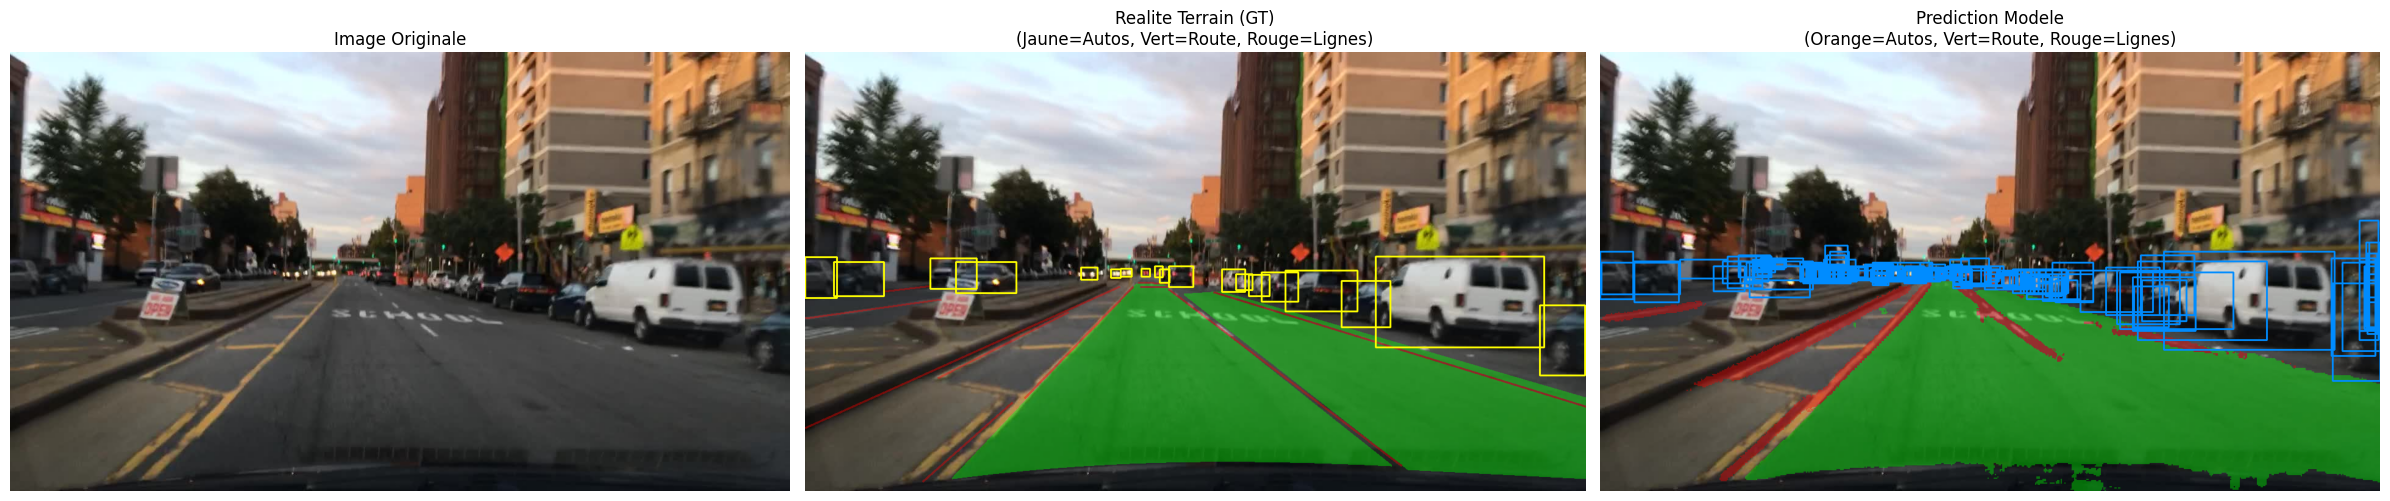

Visualisation generee pour : b1c66a42-6f7d68ca.jpg


In [8]:
if __name__ == "__main__":
    print("\n" + "="*70)
    print("DIAGNOSTIC MATERIEL")
    print("="*70)
    
    # PyTorch
    if torch.cuda.is_available():
        print(f"PyTorch : CUDA (GPU)")
        print(f"  Carte Graphique : {torch.cuda.get_device_name(0)}")
        print(f"  Memoire VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    else:
        print("PyTorch : CPU")
    
    print("-" * 70)
    providers = ort.get_available_providers()
    print(f"ONNX Runtime Providers : {providers}")
    
    if 'CUDAExecutionProvider' in providers:
        print("ONNX peut utiliser le GPU (CUDA detecte)")
    else:
        print("ONNX utilisera le CPU")
    print("="*70 + "\n")
    
    if os.path.exists(ONNX_PATH):
        audit_model_robust(ONNX_PATH)
    
    need_debug = ENABLE_LAYER_MINMAX_PLOT or (LAYER_VALUE_DISTRIBUTION is not None)
    
    concat_nodes_names = [item[0] for item in NODES_TO_ANALYZE_CONCAT]
    all_targets = NODES_TO_ANALYZE_CRITIQUE + concat_nodes_names
    
    if BATCH_SIZE == 1 and (need_debug or NODES_TO_ANALYZE_CONCAT) and len(all_targets) > 0:
        create_debug_model(ONNX_PATH, ONNX_DEBUG_PATH, target_nodes=all_targets)
    
    if not os.path.exists(VAL_DIR):
        print(f"ERREUR : Dossier introuvable : {VAL_DIR}")
    elif not os.path.exists(ONNX_PATH):
        print(f"ERREUR : Modele introuvable : {ONNX_PATH}")
    else:
        # Evaluation globale avec batch
        print("\n" + "="*70)
        print("EVALUATION GLOBALE DU DATASET")
        print("="*70)
        evaluator = DatasetFull(VAL_DIR, ONNX_PATH, max_images=MAX_IMAGES, batch_size=BATCH_SIZE, 
                               concat_config=NODES_TO_ANALYZE_CONCAT, debug_path=ONNX_DEBUG_PATH)
        evaluator.process_all()
        evaluator.compute_metrics()
        
        # Visualisation d'une image specifique
        print("\n" + "="*70)
        print("VISUALISATION D'UNE IMAGE")
        print("="*70)
        target_path = os.path.join(VAL_DIR, TARGET_IMG)
        
        if os.path.exists(target_path):
            try:
                vis_obj = DatasetImage(target_path, ONNX_PATH, debug_model_path=ONNX_DEBUG_PATH)
                vis_obj.load_ground_truth()
                
                if BATCH_SIZE == 1 and need_debug and len(all_targets) > 0:
                    print("Mode diagnostic active : capture des nodess intermediaires...")
                    vis_obj.run_inference(capture_intermediates=True)
                else:
                    vis_obj.run_inference(capture_intermediates=False)
                
                vis_obj.visualize()
                print(f"Visualisation generee pour : {TARGET_IMG}")
                
                if BATCH_SIZE == 1 and ENABLE_LAYER_MINMAX_PLOT and len(all_targets) > 0:
                    print("\nGeneration du diagramme min/max par nodes...")
                    vis_obj.plot_layer_minmax()
                
                if BATCH_SIZE == 1 and len(vis_obj.layer_outputs) > 0:
                    print(f"\nGeneration des distributions pour {len(vis_obj.layer_outputs)} nodes...")
                    
                    for idx in sorted(vis_obj.layer_outputs.keys()):
                        node_name = vis_obj.layer_names[idx]
                        print(f"  -> Distribution pour : {node_name}")
                        vis_obj.plot_layer_distribution(idx)
                        
                if BATCH_SIZE == 1 and NODES_TO_ANALYZE_CONCAT:
                    vis_obj.plot_concat_specifics(NODES_TO_ANALYZE_CONCAT)
                    
            except Exception as e:
                print(f"Erreur visualisation : {e}")
                import traceback
                traceback.print_exc()
        else:
            print(f"Image cible introuvable : {target_path}")
